# So sánh train và test theo LOSO

Ngày 18/11/2026.

So sánh Dummy, LR mặc định, LR cân bằng lớp và LR chọn đặc trưng.
Mỗi lượt fit trên 14 người train rồi tính Macro-F1 và Balanced Accuracy trên train và người test.
Với LR chọn đặc trưng, giữ k đã được inner GroupKFold chọn ở thí nghiệm gốc.

Đối chiếu dự đoán test với kết quả đã lưu trước khi chấp nhận điểm train mới.
Các đường trong hình nối các người test theo thứ tự mã người; không biểu diễn epoch.


In [1]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
from time import perf_counter
import os
import sys
import json
import hashlib
import warnings
import shutil

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/wesad/models.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Không tìm thấy thư mục dự án.")
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("MPLCONFIGDIR", str(Path(os.environ["TEMP"]) / "wesad_matplotlib"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, balanced_accuracy_score
from threadpoolctl import threadpool_limits
from wesad.data import SUBJECTS, load_feature_table
from wesad.evaluation import task_target
from wesad.models import build_pipeline
from wesad.utils import file_hash, fingerprint, environment, write_json, provenance

plt.switch_backend("Agg")
NOTEBOOK = ROOT / "notebooks/04_evaluation/Thai_train_test_comparison.ipynb"
OUT = ROOT / "outputs/notebook_research/THAI_Train_Test_Comparison"
ARCHIVE = ROOT / "experiments/04_evaluation/THAI_Train_Test_Comparison"
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
RUNS = {
    "THAI-EXP-001": "Dummy",
    "THAI-EXP-002": "LR",
    "THAI-EXP-003": "LR balanced",
    "THAI-EXP-004": "LR selected",
}
print("Python:", sys.executable)
print("Kết quả:", OUT)


Python: C:\Users\Home\Desktop\final_ML\DOAN\SGU26_Group09_Machine_Learning\wesad-stress-detection\.venv\Scripts\python.exe
Kết quả: C:\Users\Home\Desktop\final_ML\DOAN\SGU26_Group09_Machine_Learning\wesad-stress-detection\outputs\notebook_research\THAI_Train_Test_Comparison


Matplotlib is building the font cache; this may take a moment.


## Kiểm tra nguồn kết quả

In [2]:
sources = {}
for experiment in RUNS:
    folder = ROOT / "outputs/notebook_research" / experiment / "r02_main"
    manifest = json.loads((folder / "config.json").read_text(encoding="utf-8"))
    summary = json.loads((folder / "summary.json").read_text(encoding="utf-8"))
    assert summary["status"] == "complete", experiment
    assert manifest["environment"] == environment(), "Môi trường khác kết quả gốc."
    sources[experiment] = {"folder": folder, "manifest": manifest,
                           "metrics": pd.read_csv(folder / "metrics_by_subject.csv"),
                           "predictions": pd.read_csv(folder / "predictions.csv")}
reference = sources["THAI-EXP-002"]["manifest"]
settings = reference["settings"]
FEATURES = ROOT / "data/features/g2_physiological68_group15_20261107/all_subjects.csv"
SCHEMA = FEATURES.parent / "feature_schema.json"
df, feature_columns = load_feature_table(FEATURES, SCHEMA, SUBJECTS)
assert file_hash(FEATURES) == reference["data_sha256"]
core_hash = fingerprint({path: hashlib.sha256((ROOT / path).read_bytes().replace(b"\r\n", b"\n")).hexdigest()
                         for path in settings["source_paths"]})
for experiment, source in sources.items():
    m = source["manifest"]
    expected_code = m.get("shared_code_sha256", m["code_sha256"])
    assert core_hash == expected_code, experiment
    assert m["data_sha256"] == reference["data_sha256"]
    assert m["feature_columns"] == feature_columns
    metrics = source["metrics"]
    assert len(metrics) == 30 and not metrics.duplicated(["task", "subject_id"]).any()
    for receipt in source["folder"].glob("folds/*/*/*/complete.json"):
        complete = json.loads(receipt.read_text())
        assert complete["signature"] == m["signature"]
        assert all(file_hash(receipt.parent / name) == value for name, value in complete["files"].items())
analysis_source = json.loads(NOTEBOOK.read_text(encoding="utf-8"))
code_hash = fingerprint(["".join(c["source"]) for c in analysis_source["cells"] if c["cell_type"] == "code"])
write_json(OUT / "analysis_config.json", {
    "created_at": datetime.now(ZoneInfo("Asia/Ho_Chi_Minh")).isoformat(),
    "scope": "outer_train_resubstitution_and_outer_test_LOSO",
    "data_sha256": file_hash(FEATURES), "shared_code_sha256": core_hash,
    "notebook_code_sha256": code_hash, "environment": environment(), **provenance(),
    "source_runs": {key: {"path": src["folder"].relative_to(ROOT).as_posix(),
                           "signature": src["manifest"]["signature"],
                           "metrics_sha256": file_hash(src["folder"] / "metrics_by_subject.csv"),
                           "predictions_sha256": file_hash(src["folder"] / "predictions.csv")}
                    for key, src in sources.items()},
})
print("PASS: dữ liệu, môi trường, mã nguồn và 120 fold gốc hợp lệ.")


PASS: dữ liệu, môi trường, mã nguồn và 120 fold gốc hợp lệ.


## Fit lại và tính điểm train–test

Giữ nguyên pipeline và tham số của từng fold. Chỉ chấp nhận kết quả khi dự đoán test khớp hoàn toàn bản gốc.

In [3]:
X = df[feature_columns].astype(float)
records, evidence = [], {}
for experiment, source in sources.items():
    config = source["manifest"]["settings"]
    for _, original_metric in source["metrics"].iterrows():
        task, subject = original_metric.task, original_metric.subject_id
        model_name = original_metric.model
        folder = source["folder"] / "folds" / task / model_name / subject
        details = json.loads((folder / "details.json").read_text())
        y, labels = task_target(df, task)
        train = np.flatnonzero(df.subject_id.ne(subject))
        test = np.flatnonzero(df.subject_id.eq(subject))
        assert set(df.subject_id.iloc[train]) == set(details["outer_train_subjects"])
        assert set(df.subject_id.iloc[test]) == set(details["outer_test_subjects"]) == {subject}
        assert set(df.subject_id.iloc[train]).isdisjoint(df.subject_id.iloc[test])
        selected_k = None
        if experiment == "THAI-EXP-004":
            selected_k = int(details["best_params"]["selection__k"])
            pipeline = Pipeline([
                ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
                ("scaler", StandardScaler()),
                ("selection", SelectKBest(score_func=f_classif, k=selected_k)),
                ("model", LogisticRegression(**config["model_params"]["lr"])),
            ])
        else:
            pipeline = build_pipeline(model_name, config)
            if details.get("best_params"):
                pipeline.set_params(**details["best_params"])
        started = perf_counter()
        with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=1):
            warnings.simplefilter("always")
            pipeline.fit(X.iloc[train], y.iloc[train])
            pred_train = pipeline.predict(X.iloc[train])
            pred_test = pipeline.predict(X.iloc[test])
        if selected_k is not None:
            names = [name for name, keep in zip(feature_columns, pipeline["selection"].get_support()) if keep]
            assert names == details["selected_features"]
        reproduced = df.iloc[test][["subject_id", "window_id"]].copy()
        reproduced["y_true"], reproduced["y_pred"] = y.iloc[test].to_numpy(), pred_test
        saved = pd.read_csv(folder / "predictions.csv")
        paired = reproduced.merge(saved, on=["subject_id", "window_id"], suffixes=("_new", "_old"), validate="one_to_one")
        assert len(paired) == len(test) == int(original_metric.n_test)
        assert paired.y_true_new.eq(paired.y_true_old).all()
        assert paired.y_pred_new.eq(paired.y_pred_old).all(), f"Dự đoán không khớp: {experiment}/{task}/{subject}"
        row = {"experiment": experiment, "model": RUNS[experiment], "task": task, "subject_id": subject,
               "n_train": len(train), "n_test": len(test), "selected_k": selected_k,
               "test_predictions_verified": True, "seconds": round(perf_counter() - started, 4)}
        for split, truth, prediction in [("train", y.iloc[train], pred_train), ("test", y.iloc[test], pred_test)]:
            row[f"{split}_macro_f1"] = float(f1_score(truth, prediction, labels=labels, average="macro", zero_division=0))
            row[f"{split}_balanced_accuracy"] = float(balanced_accuracy_score(truth, prediction))
        assert np.isclose(row["test_macro_f1"], original_metric.macro_f1, atol=1e-12, rtol=0)
        assert np.isclose(row["test_balanced_accuracy"], original_metric.balanced_accuracy, atol=1e-12, rtol=0)
        for metric in ["macro_f1", "balanced_accuracy"]:
            row[f"{metric}_gap"] = row[f"train_{metric}"] - row[f"test_{metric}"]
        key = f"{experiment}/{task}/{subject}"
        evidence[key] = {"outer_train_subjects": details["outer_train_subjects"],
                         "outer_test_subjects": [subject], "selected_k": selected_k,
                         "test_predictions_verified": True,
                         "original_completion_sha256": file_hash(folder / "complete.json"),
                         "original_predictions_sha256": file_hash(folder / "predictions.csv"),
                         "warnings": sorted(set(str(w.message) for w in caught))}
        records.append(row)
        print(f"{key}: train F1={row['train_macro_f1']:.4f}; test F1={row['test_macro_f1']:.4f}", flush=True)
metrics_tt = pd.DataFrame(records)
assert len(metrics_tt) == 120
assert not metrics_tt.duplicated(["experiment", "task", "subject_id"]).any()
metrics_tt.to_csv(OUT / "train_test_metrics.csv", index=False)
write_json(OUT / "verification.json", {"n_folds": 120, "all_test_predictions_match": True, "folds": evidence})
display(metrics_tt)


THAI-EXP-001/multiclass/S10: train F1=0.2353; test F1=0.2311
THAI-EXP-001/multiclass/S11: train F1=0.2350; test F1=0.2350
THAI-EXP-001/multiclass/S13: train F1=0.2351; test F1=0.2343
THAI-EXP-001/multiclass/S14: train F1=0.2352; test F1=0.2321
THAI-EXP-001/multiclass/S15: train F1=0.2351; test F1=0.2340
THAI-EXP-001/multiclass/S16: train F1=0.2350; test F1=0.2350
THAI-EXP-001/multiclass/S17: train F1=0.2353; test F1=0.2311
THAI-EXP-001/multiclass/S2: train F1=0.2348; test F1=0.2378
THAI-EXP-001/multiclass/S3: train F1=0.2350; test F1=0.2348
THAI-EXP-001/multiclass/S4: train F1=0.2349; test F1=0.2364
THAI-EXP-001/multiclass/S5: train F1=0.2348; test F1=0.2381
THAI-EXP-001/multiclass/S6: train F1=0.2350; test F1=0.2362
THAI-EXP-001/multiclass/S7: train F1=0.2348; test F1=0.2379
THAI-EXP-001/multiclass/S8: train F1=0.2350; test F1=0.2348
THAI-EXP-001/multiclass/S9: train F1=0.2349; test F1=0.2372
THAI-EXP-001/binary/S10: train F1=0.4127; test F1=0.4059
THAI-EXP-001/binary/S11: train F1=0.

,experiment,model,task,subject_id,n_train,n_test,selected_k,test_predictions_verified,seconds,train_macro_f1,train_balanced_accuracy,test_macro_f1,test_balanced_accuracy,macro_f1_gap,balanced_accuracy_gap
0,THAI-EXP-001,Dummy,multiclass,S10,5763,426,NaN,True,0.5390,0.235321,0.333333,0.231084,0.333333,0.004237,0.000000
1,THAI-EXP-001,Dummy,multiclass,S11,5772,417,NaN,True,0.1064,0.235035,0.333333,0.234990,0.333333,0.000045,0.000000
2,THAI-EXP-001,Dummy,multiclass,S13,5772,417,NaN,True,0.0984,0.235083,0.333333,0.234318,0.333333,0.000765,0.000000
3,THAI-EXP-001,Dummy,multiclass,S14,5779,410,NaN,True,0.0877,0.235237,0.333333,0.232114,0.333333,0.003123,0.000000
4,THAI-EXP-001,Dummy,multiclass,S15,5771,418,NaN,True,0.1073,0.235109,0.333333,0.233954,0.333333,0.001155,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,THAI-EXP-004,LR selected,binary,S13,5772,417,16.0,True,0.1726,0.979071,0.978034,0.558181,0.686007,0.420889,0.292027
116,THAI-EXP-004,LR selected,binary,S14,5779,410,32.0,True,0.1887,0.990275,0.990030,0.705713,0.682540,0.284562,0.307490
117,THAI-EXP-004,LR selected,binary,S15,5771,418,16.0,True,0.1849,0.968751,0.965930,0.784165,0.752640,0.184586,0.213290
118,THAI-EXP-004,LR selected,binary,S16,5774,415,16.0,True,0.1693,0.969331,0.968392,1.000000,1.000000,-0.030669,-0.031608


## Tổng hợp theo 15 người test

In [4]:
score_columns = ["train_macro_f1", "test_macro_f1", "macro_f1_gap",
                 "train_balanced_accuracy", "test_balanced_accuracy", "balanced_accuracy_gap"]
summary_tt = metrics_tt.groupby(["experiment", "task"])[score_columns].agg(["mean", "std"])
display(summary_tt)
summary_export = summary_tt.copy()
summary_export.columns = [f"{metric}_{stat}" for metric, stat in summary_export.columns]
summary_export.reset_index().to_csv(OUT / "train_test_summary.csv", index=False)


train_macro_f1  ...          
                                  mean  ...       std
experiment   task                       ...          
THAI-EXP-001 binary           0.412251  ...  0.000000
             multiclass       0.235032  ...  0.000000
THAI-EXP-002 binary           0.997974  ...  0.175804
             multiclass       0.989547  ...  0.141806
THAI-EXP-003 binary           0.997084  ...  0.170023
             multiclass       0.987114  ...  0.144366
THAI-EXP-004 binary           0.976170  ...  0.136050
             multiclass       0.906562  ...  0.170935

[8 rows x 12 columns]

## Điểm train và test theo từng fold LOSO

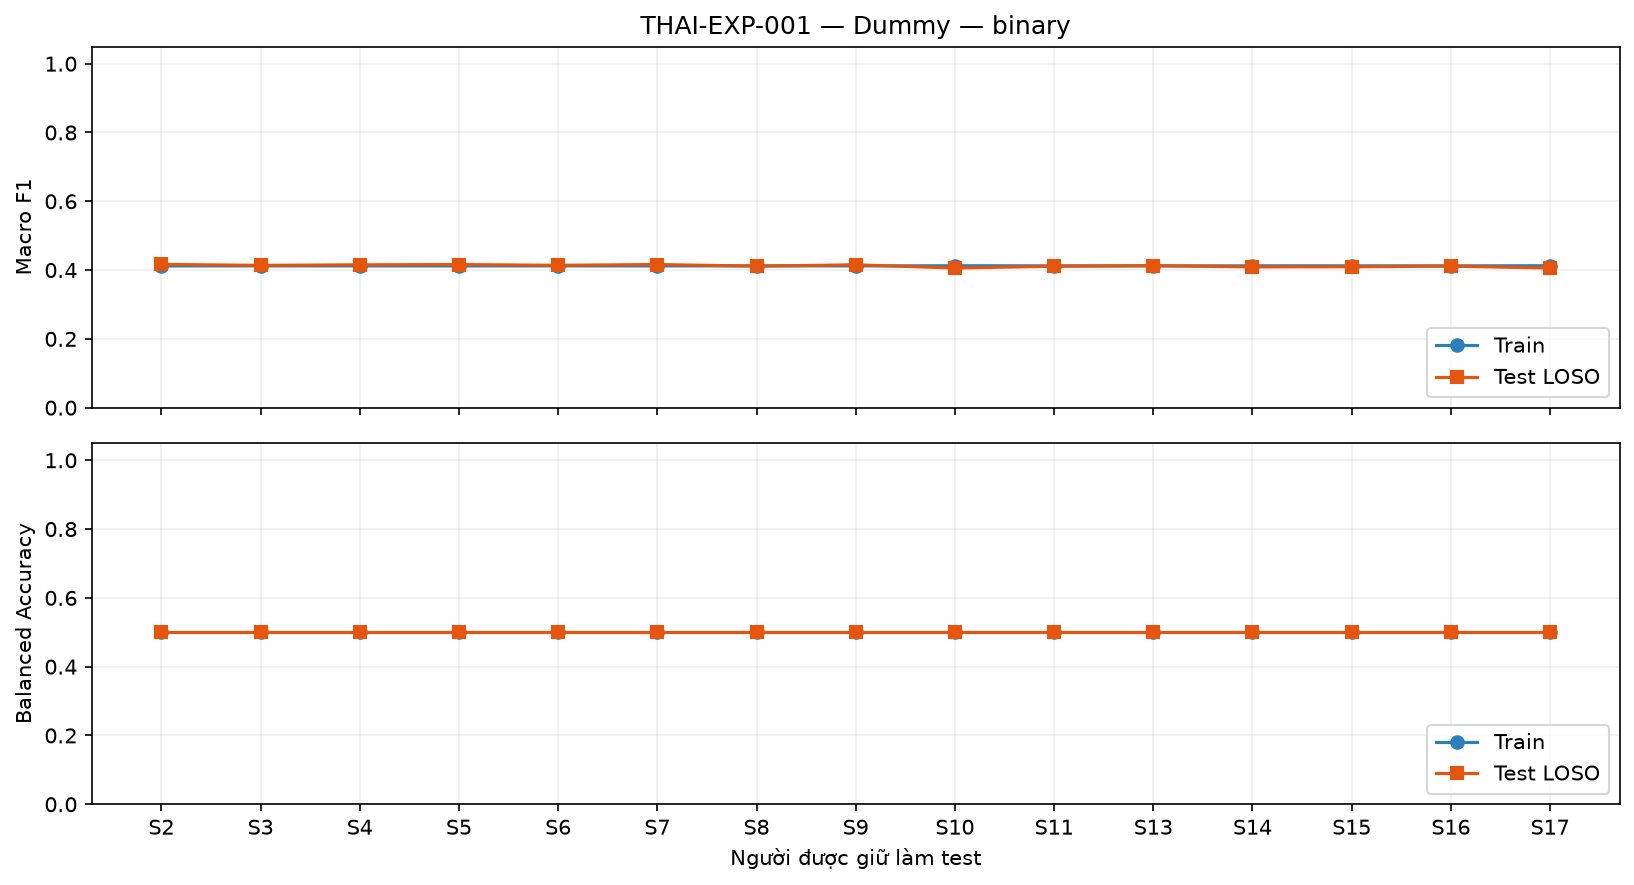

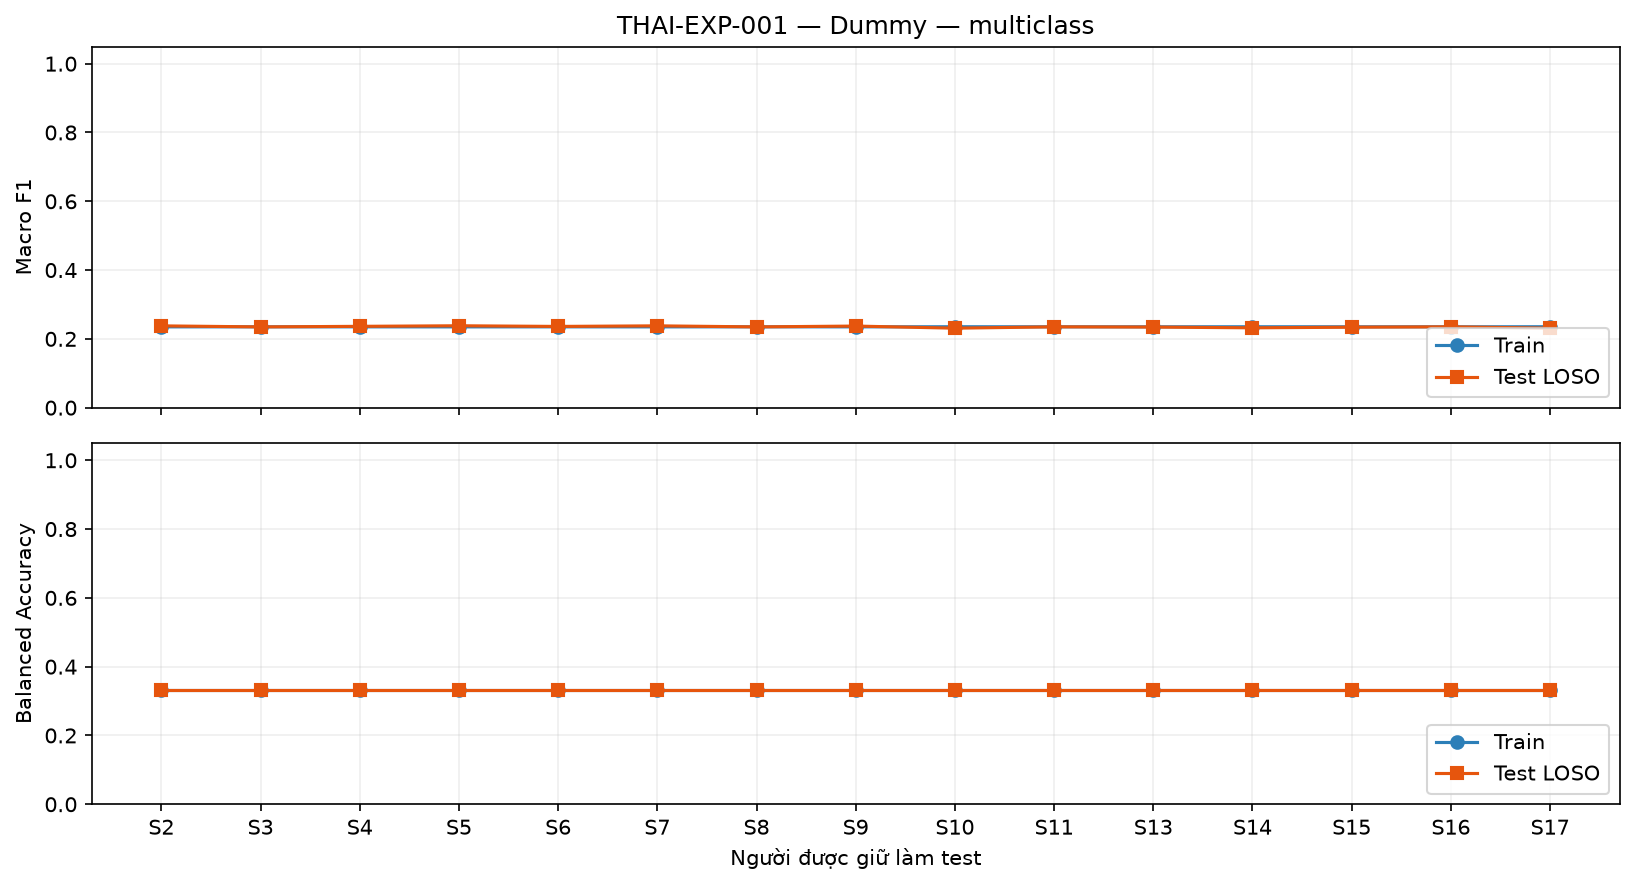

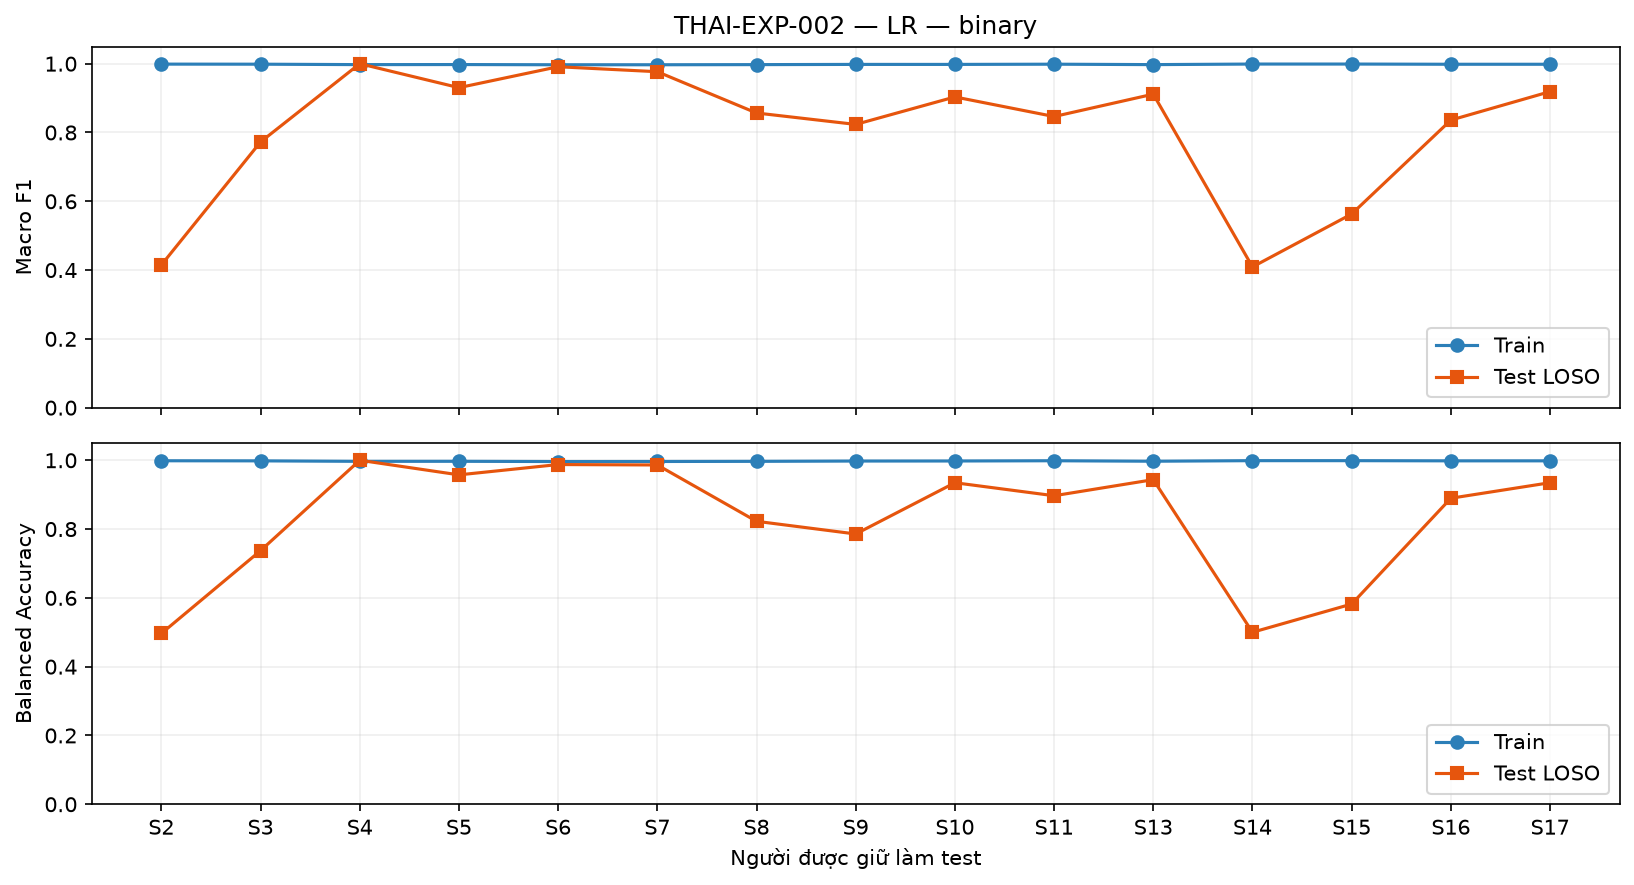

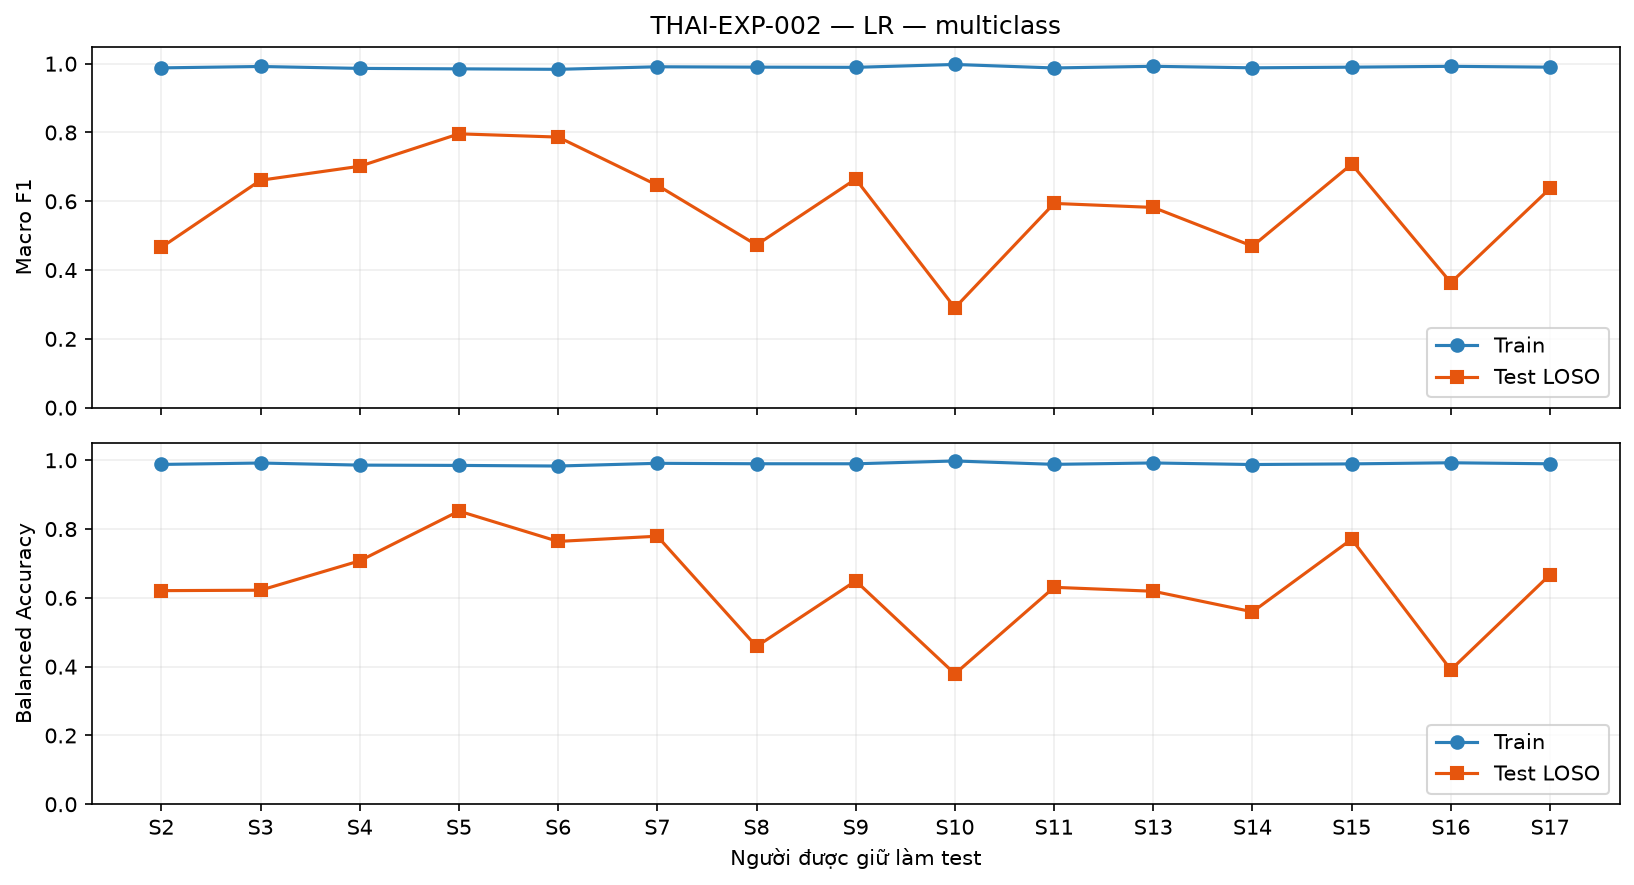

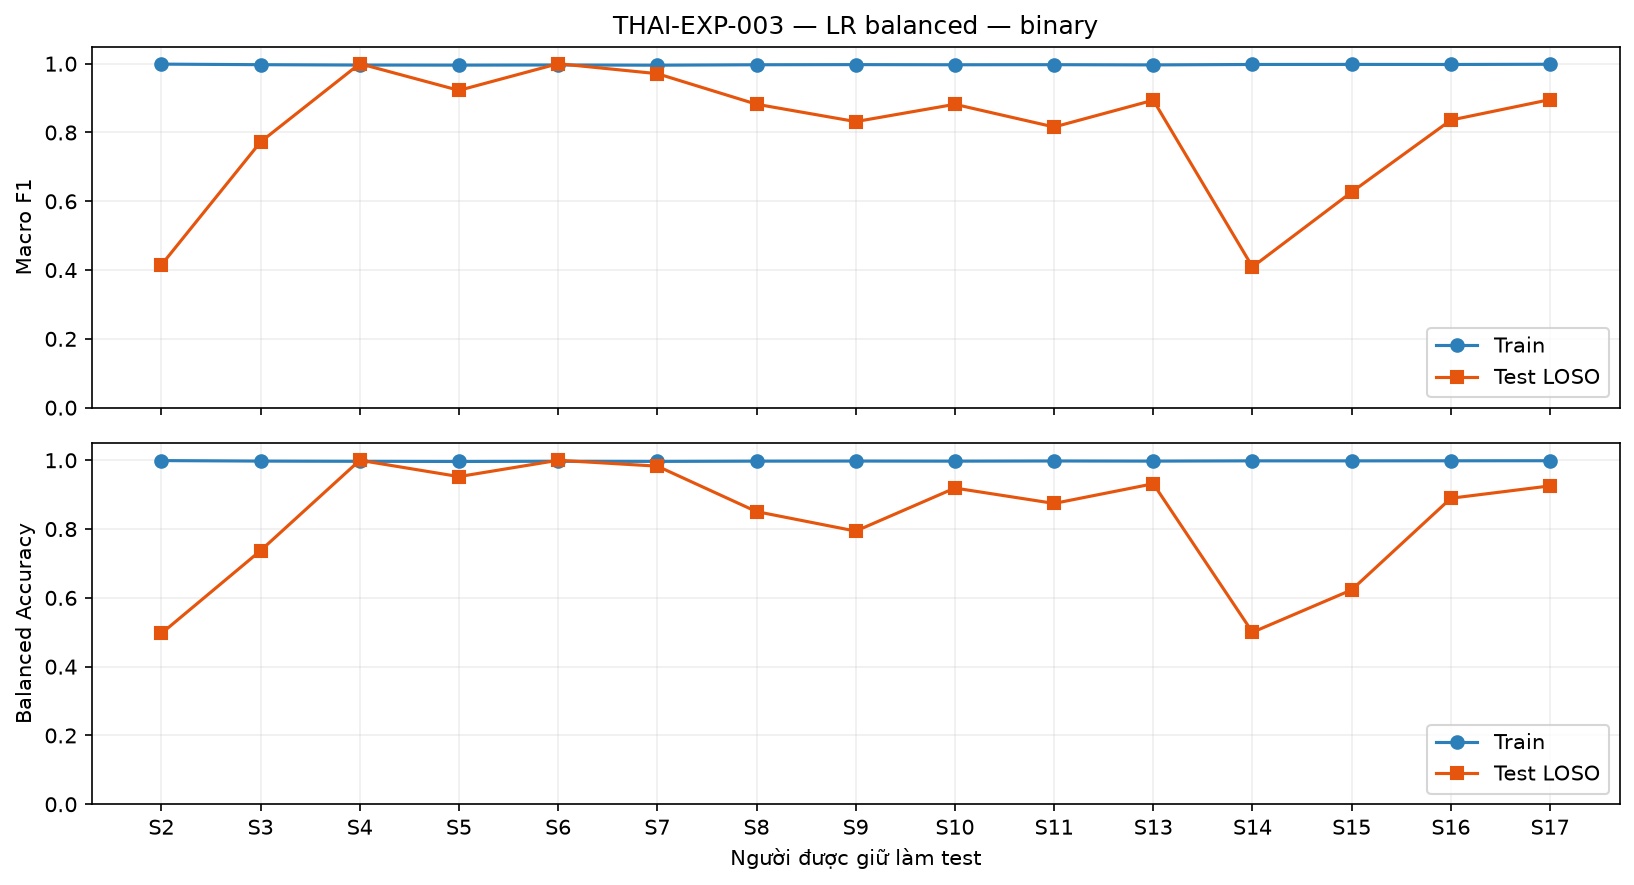

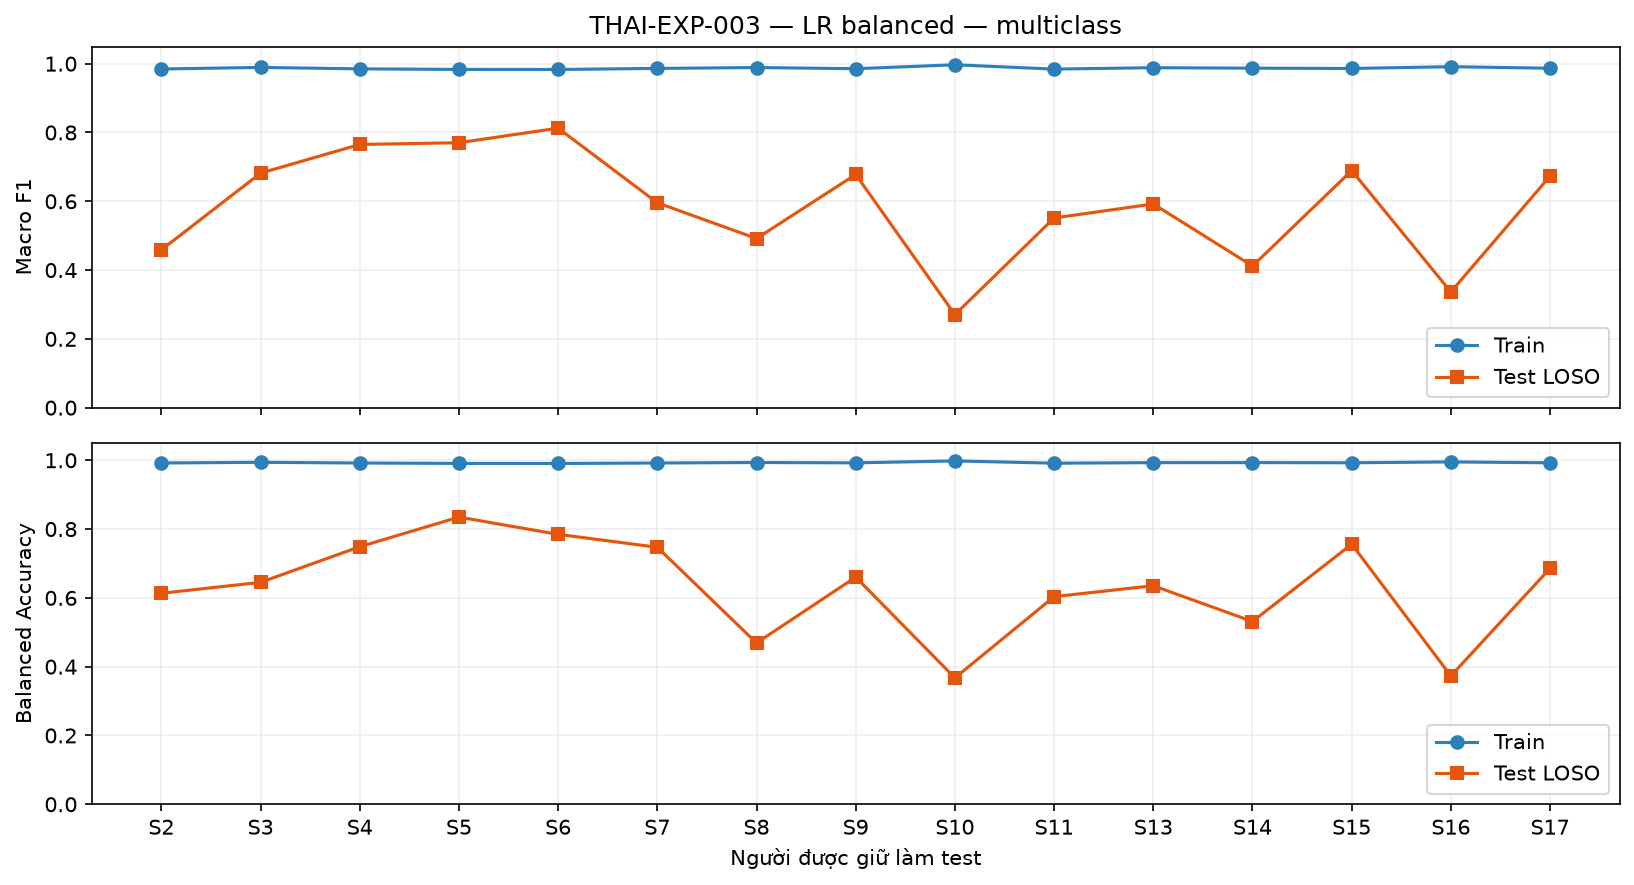

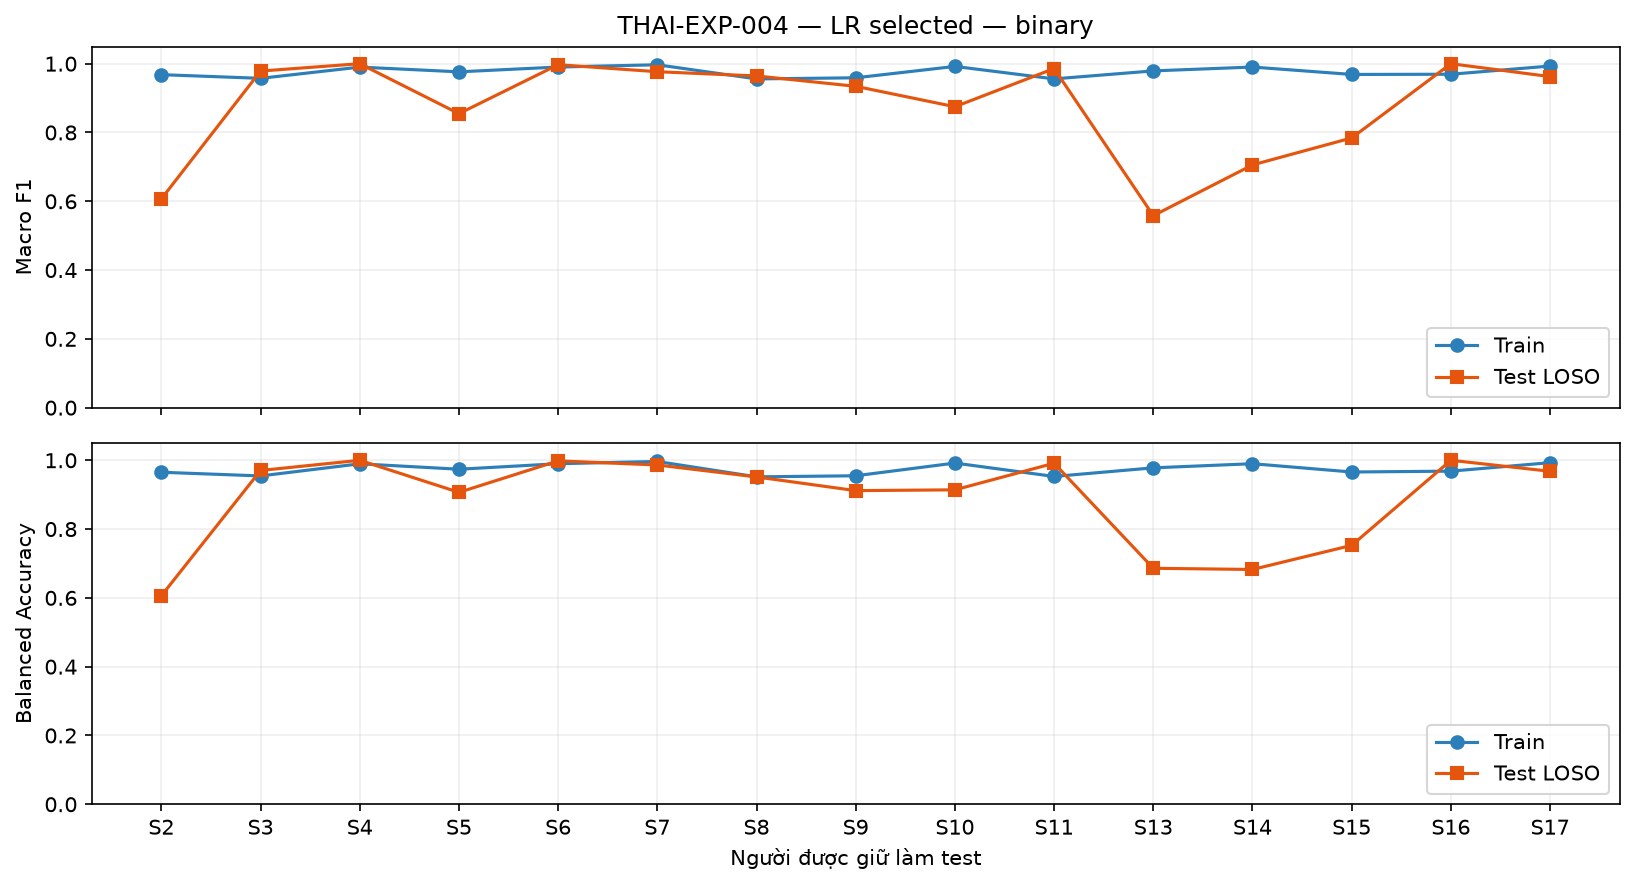

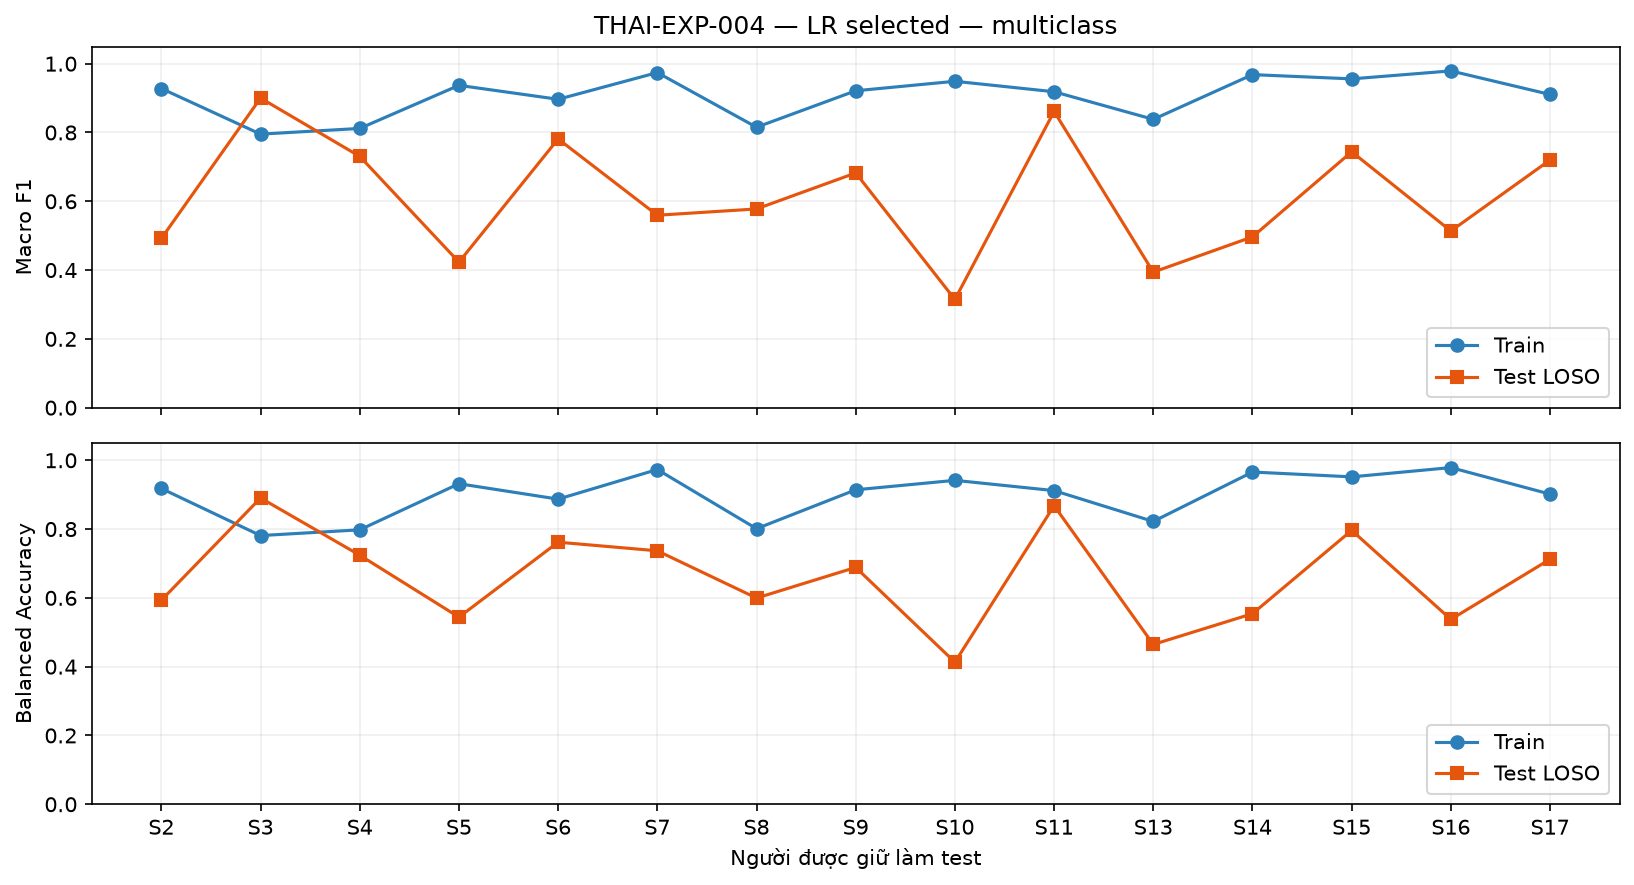

In [5]:
def show_figure(fig, name):
    fig.tight_layout()
    filename = FIGURES / name
    fig.savefig(filename, dpi=150, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(filename)))

for experiment, label in RUNS.items():
    for task in ["binary", "multiclass"]:
        part = metrics_tt.loc[metrics_tt.experiment.eq(experiment) & metrics_tt.task.eq(task)].set_index("subject_id").reindex(SUBJECTS)
        fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
        for ax, metric in zip(axes, ["macro_f1", "balanced_accuracy"]):
            ax.plot(part.index, part[f"train_{metric}"], marker="o", label="Train", color="#2c7fb8")
            ax.plot(part.index, part[f"test_{metric}"], marker="s", label="Test LOSO", color="#e6550d")
            ax.set(ylabel=metric.replace("_", " ").title(), ylim=(0, 1.05))
            ax.grid(alpha=0.2)
            ax.legend(loc="lower right")
        axes[0].set_title(f"{experiment} — {label} — {task}")
        axes[1].set_xlabel("Người được giữ làm test")
        show_figure(fig, f"{experiment}_{task}_train_test.png")


## So sánh điểm trung bình giữa các cấu hình

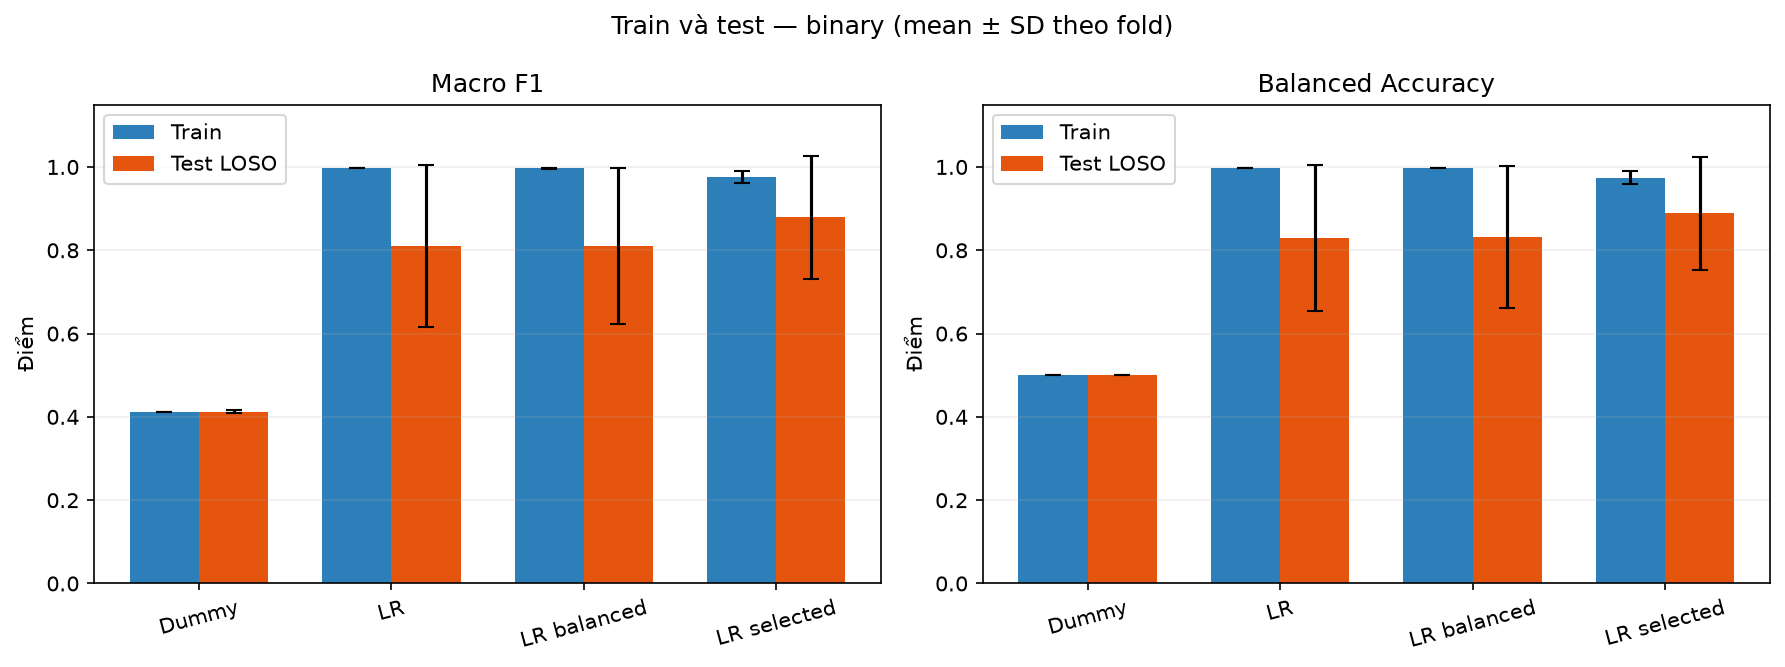

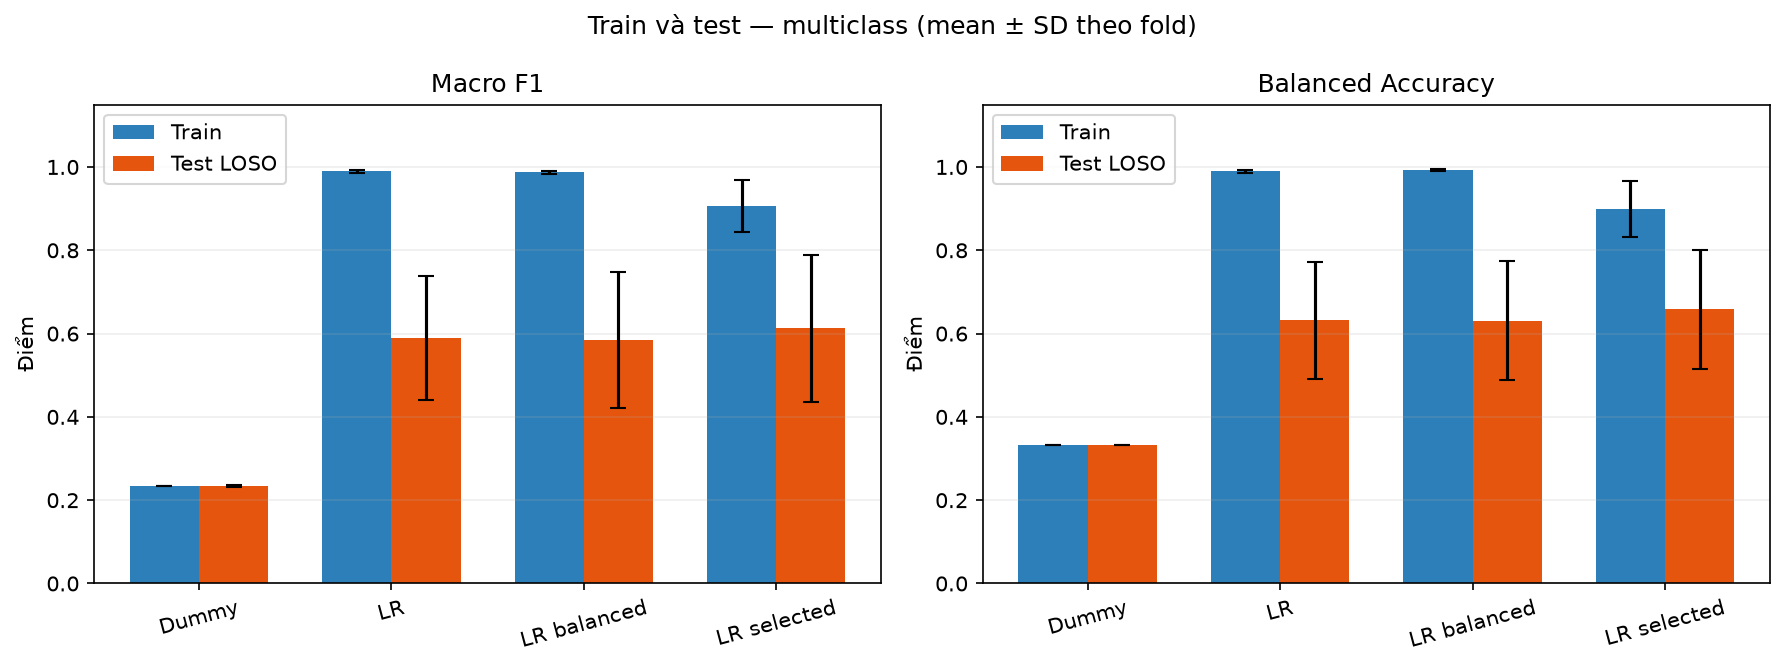

In [6]:
for task in ["binary", "multiclass"]:
    table = metrics_tt.loc[metrics_tt.task.eq(task)].groupby("experiment")[score_columns].agg(["mean", "std"]).reindex(RUNS)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    x = np.arange(len(RUNS))
    for ax, metric in zip(axes, ["macro_f1", "balanced_accuracy"]):
        ax.bar(x - 0.18, table[(f"train_{metric}", "mean")], width=0.36,
               yerr=table[(f"train_{metric}", "std")], capsize=4, label="Train", color="#2c7fb8")
        ax.bar(x + 0.18, table[(f"test_{metric}", "mean")], width=0.36,
               yerr=table[(f"test_{metric}", "std")], capsize=4, label="Test LOSO", color="#e6550d")
        ax.set(xticks=x, xticklabels=list(RUNS.values()), ylim=(0, 1.15), ylabel="Điểm",
               title=metric.replace("_", " ").title())
        ax.tick_params(axis="x", rotation=15)
        ax.grid(axis="y", alpha=0.2)
        ax.legend()
    fig.suptitle(f"Train và test — {task} (mean ± SD theo fold)")
    show_figure(fig, f"summary_{task}_train_test.png")


## Cách đọc kết quả

- Điểm train được tính lại trên chính các cửa sổ dùng để fit, nên thường lạc quan hơn test.
- Điểm test được tính trên người không xuất hiện trong train và đã đối chiếu với dự đoán gốc.
- Gap = điểm train − điểm test. Gap lớn cho thấy khoảng cách tổng quát hóa sang người mới; chưa đủ để xác định nguyên nhân là overfitting hay khác biệt giữa các người.
- Điểm train/test trung bình và SD được tính theo fold. Các tập train giữa các fold chồng lặp, không phải 15 phép thử độc lập.
- Không dùng đồ thị test này để chọn lại tham số hoặc số đặc trưng rồi coi kết quả là đánh giá độc lập.


In [7]:
ARCHIVE.mkdir(parents=True, exist_ok=True)
for name in ["analysis_config.json", "train_test_metrics.csv", "train_test_summary.csv", "verification.json"]:
    shutil.copy2(OUT / name, ARCHIVE / name)
shutil.copytree(FIGURES, ARCHIVE / "figures", dirs_exist_ok=True)
print("Đã lưu 10 hình và bảng train–test:", OUT)


Đã lưu 10 hình và bảng train–test: C:\Users\Home\Desktop\final_ML\DOAN\SGU26_Group09_Machine_Learning\wesad-stress-detection\outputs\notebook_research\THAI_Train_Test_Comparison


## Nhận xét từ kết quả

Macro-F1 trung bình theo 15 fold:

| Cấu hình | Bài toán | Train | Test | Gap |
|---|---|---:|---:|---:|
| Dummy | binary | 0.412251 | 0.412281 | -0.000030 |
| Dummy | multiclass | 0.235032 | 0.235047 | -0.000016 |
| LR | binary | 0.997974 | 0.810269 | 0.187705 |
| LR | multiclass | 0.989547 | 0.589391 | 0.400156 |
| LR balanced | binary | 0.997084 | 0.810281 | 0.186803 |
| LR balanced | multiclass | 0.987114 | 0.585266 | 0.401847 |
| LR selected | binary | 0.976170 | 0.878943 | 0.097227 |
| LR selected | multiclass | 0.906562 | 0.612709 | 0.293853 |

LR mặc định và LR cân bằng lớp có điểm train gần 1 nhưng điểm test thấp hơn rõ rệt, nhất là multiclass. LR chọn đặc trưng giảm điểm train và tăng điểm test trung bình so với LR mặc định; vẫn có người test có điểm thấp.
Khoảng cách train–test cho thấy cần thận trọng với khả năng tổng quát hóa sang người mới. Phân tích này chưa xác định riêng tác động của overfitting, khác biệt sinh lý giữa người và chất lượng tín hiệu.